# Decoding hand movements from muscle signals
   Classifying 12 finger movements from 10-channel surface EMG (NinaPro DB1, Exercise 1), one model per person, then testing how accuracy changes as electrodes are removed.

   ## 0. Set-up

In [2]:
# ============================================================
# 0.1  SET-UP: package versions, random seed, project folders
# ============================================================
# Goal: anyone who re-runs this notebook gets exactly the same numbers.

import platform
import random
from pathlib import Path

import numpy as np                # arrays and maths
import scipy                      # scientific tools (it reads MATLAB files)
import pandas as pd               # tables
import matplotlib                 # plotting library (imported here for its version)
import matplotlib.pyplot as plt   # the plotting functions we use later
import sklearn                    # scikit-learn: the machine-learning library

# --- 1. Print the exact software versions (they go into requirements.txt later)
print("Python".ljust(14), platform.python_version())
packages = {"numpy": np, "scipy": scipy, "pandas": pd,
            "matplotlib": matplotlib, "scikit-learn": sklearn}
for name, module in packages.items():
    print(name.ljust(14), module.__version__)

# --- 2. Fix the random seed so "random" steps repeat exactly.
#        (scikit-learn models will also get random_state=SEED later.)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# --- 3. Decide where files live.
#        Colab's own disk is wiped when a session ends; Google Drive is not.
#        Set USE_DRIVE = False to run without Drive (data re-downloads each session).
USE_DRIVE = True
try:
    from google.colab import drive    # this module only exists inside Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and USE_DRIVE:
    drive.mount("/content/drive")     # a pop-up asks you to allow access
    PROJECT_DIR = Path("/content/drive/MyDrive/emg-ninapro")
else:
    PROJECT_DIR = Path.cwd()          # e.g. the repository folder on a laptop

DATA_DIR = PROJECT_DIR / "data"       # NinaPro files: downloaded, never re-hosted
FIG_DIR = PROJECT_DIR / "figures"     # PNG figures for the README
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("\nRunning in Colab:", IN_COLAB)
print("Data folder:   ", DATA_DIR)
print("Figure folder: ", FIG_DIR)

Python         3.13.18
numpy          2.4.6
scipy          1.16.3
pandas         2.2.3
matplotlib     3.10.0
scikit-learn   1.6.1
Mounted at /content/drive

Running in Colab: True
Data folder:    /content/drive/MyDrive/emg-ninapro/data
Figure folder:  /content/drive/MyDrive/emg-ninapro/figures


### 0.2 Download the data
   NinaPro DB1 (Atzori et al., 2014, *Scientific Data*, doi:10.1038/sdata.2014.53), downloaded from the official site when the notebook runs. The data are not redistributed in this repository.

In [3]:
# ============================================================
# 0.2  DOWNLOAD: NinaPro DB1, Exercise 1 only, all 27 subjects
# ============================================================
# Each subject's zip holds three MATLAB files, one per exercise.
# We keep only Exercise 1 (name ends in _E1.mat) and let the zip be deleted.
# Safe to re-run: subjects already downloaded are skipped.

import re
import shutil
import tempfile
import time
import urllib.request
import zipfile
import scipy.io

URL = "https://ninapro.hevs.ch/files/DB1/Preprocessed/s{n}.zip"   # linked from the DB1 page
SUBJECTS = range(1, 28)                                            # subjects 1 to 27
NEEDED = {"emg", "restimulus", "rerepetition"}                     # variables we will use

def e1_file(n):
    """Path of subject n's Exercise 1 file in our data folder."""
    return DATA_DIR / f"S{n}_A1_E1.mat"

for n in SUBJECTS:
    target = e1_file(n)
    if target.exists():
        print(f"S{n:>2}: already downloaded")
        continue
    start = time.time()
    with tempfile.TemporaryDirectory() as tmp:          # temporary folder, deleted automatically
        zip_path = Path(tmp) / f"s{n}.zip"
        request = urllib.request.Request(URL.format(n=n), headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(request, timeout=300) as response, open(zip_path, "wb") as out:
            shutil.copyfileobj(response, out)           # zip goes to Colab's fast local disk
        with zipfile.ZipFile(zip_path) as z:
            # Find the Exercise 1 file; skip hidden macOS copies ("._..." or "__MACOSX/")
            e1 = [m for m in z.namelist()
                  if re.search(r"_E1\.mat$", m, flags=re.IGNORECASE)
                  and not Path(m).name.startswith("._") and "__MACOSX" not in m]
            if len(e1) != 1:
                raise RuntimeError(f"S{n}: expected 1 Exercise-1 file, found {e1}; zip holds {z.namelist()}")
            part = target.with_suffix(".part")          # write under a temporary name first...
            with z.open(e1[0]) as src, open(part, "wb") as dst:
                shutil.copyfileobj(src, dst)
            part.rename(target)                         # ...so a half-written file never looks finished
    print(f"S{n:>2}: saved {target.name}  ({target.stat().st_size / 1e6:.1f} MB "
          f"in {time.time() - start:.0f} s; zip entry: {e1[0]})")

# --- Check that every file opens and holds the variables we need.
#     whosmat() lists a file's variables without loading the data, so it is fast.
print("\nVariables in subject 1's file (name, shape, type):")
for name, shape, kind in scipy.io.whosmat(e1_file(1)):
    print(f"  {name:<13} {str(shape):<13} {kind}")

print("\nSubject  samples  channels  MB")
problems = []
for n in SUBJECTS:
    info = {name: shape for name, shape, kind in scipy.io.whosmat(e1_file(n))}
    missing = NEEDED - set(info)
    if missing:
        problems.append(f"S{n} is missing {sorted(missing)}")
    rows, cols = info.get("emg", ("?", "?"))
    print(f"S{n:<7} {rows:>7}  {cols:>8}  {e1_file(n).stat().st_size / 1e6:.1f}")

print("\nAll 27 files OK" if not problems else "\nPROBLEMS:\n" + "\n".join(problems))

S 1: already downloaded
S 2: already downloaded
S 3: already downloaded
S 4: already downloaded
S 5: already downloaded
S 6: already downloaded
S 7: already downloaded
S 8: already downloaded
S 9: already downloaded
S10: already downloaded
S11: already downloaded
S12: already downloaded
S13: already downloaded
S14: already downloaded
S15: already downloaded
S16: already downloaded
S17: already downloaded
S18: already downloaded
S19: already downloaded
S20: already downloaded
S21: already downloaded
S22: already downloaded
S23: already downloaded
S24: already downloaded
S25: already downloaded
S26: already downloaded
S27: already downloaded

Variables in subject 1's file (name, shape, type):
  emg           (101014, 10)  double
  stimulus      (101014, 1)   double
  glove         (101014, 22)  double
  subject       (1, 1)        double
  exercise      (1, 1)        double
  repetition    (101014, 1)   double
  restimulus    (101014, 1)   double
  rerepetition  (101014, 1)   double

Sub

## 1. Load and look at the data
   ### 1.1 Check one subject against the documentation

In [4]:
# ============================================================
# 1.1  LOAD one subject and check the labels
# ============================================================
# Before any modelling, check the data match the documentation:
# 12 movements x 10 repetitions, each lasting a few seconds.

FS = 100   # DB1 sampling rate: 100 samples per second

# Exercise 1 movement names, in label order 1-12 (Atzori et al. 2012, Table I)
MOVEMENTS = ["rest", "index flexion", "index extension", "middle flexion",
             "middle extension", "ring flexion", "ring extension",
             "little finger flexion", "little finger extension",
             "thumb adduction", "thumb abduction", "thumb flexion", "thumb extension"]

def load_subject(n):
    """Load subject n's Exercise 1 file.
    Returns emg (samples x 10 channels), label (0 = rest, 1-12 = movement)
    and rep (repetition number) for every sample."""
    mat = scipy.io.loadmat(e1_file(n), variable_names=["emg", "restimulus", "rerepetition"])
    emg = mat["emg"]                                # shape (N, 10)
    label = mat["restimulus"].ravel().astype(int)   # stored as decimals in shape (N, 1);
    rep = mat["rerepetition"].ravel().astype(int)   # make them whole numbers in shape (N,)
    return emg, label, rep

SUBJECT = 1
emg, label, rep = load_subject(SUBJECT)
print(f"Subject {SUBJECT}: {emg.shape[0]} samples x {emg.shape[1]} channels "
      f"= {emg.shape[0] / FS:.0f} s ({emg.shape[0] / FS / 60:.1f} min)")
print("Missing values (NaN):", int(np.isnan(emg).sum()))
print("Any negative values?  ", bool((emg < 0).any()))
print(f"Signal range:          {emg.min():.4f} to {emg.max():.4f}")
print("Labels found:         ", np.unique(label).tolist())
print("Repetitions found:    ", np.unique(rep).tolist())

# Cut the recording into blocks where label and repetition stay the same
# (one block = one repetition of one movement, or one rest period).
cut = np.flatnonzero((np.diff(label) != 0) | (np.diff(rep) != 0)) + 1
start, stop = np.r_[0, cut], np.r_[cut, len(label)]
blocks = pd.DataFrame({"label": label[start], "rep": rep[start],
                       "seconds": (stop - start) / FS})

moves = blocks[blocks.label > 0]
summary = moves.groupby("label").agg(blocks=("rep", "size"),
                                     repetitions=("rep", "nunique"),
                                     mean_s=("seconds", "mean"),
                                     min_s=("seconds", "min"),
                                     max_s=("seconds", "max"))
summary.insert(0, "movement", [MOVEMENTS[k] for k in summary.index])
print("\nMovement blocks (we expect 10 blocks = 10 repetitions per movement):")
print(summary.round(2).to_string())

rest = blocks[blocks.label == 0]
print(f"\nRest: {len(rest)} blocks, mean {rest.seconds.mean():.1f} s each; "
      f"repetition number(s) during rest: {np.unique(rep[label == 0]).tolist()}")
print(f"Share of all samples that are rest: {(label == 0).mean():.0%}")

Subject 1: 101014 samples x 10 channels = 1010 s (16.8 min)
Missing values (NaN): 0
Any negative values?   False
Signal range:          0.0000 to 4.6606
Labels found:          [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Repetitions found:     [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

Movement blocks (we expect 10 blocks = 10 repetitions per movement):
                      movement  blocks  repetitions  mean_s  min_s  max_s
label                                                                    
1                index flexion      10           10    3.82   3.05   4.38
2              index extension      10           10    2.62   1.93   3.88
3               middle flexion      10           10    4.14   1.99   5.24
4             middle extension      10           10    2.98   2.42   3.48
5                 ring flexion      10           10    3.95   3.18   4.53
6               ring extension      10           10    3.06   2.53   4.32
7        little finger flexion      10           10    2.62  

### 1.2 Figure 1: the signal with movement labels

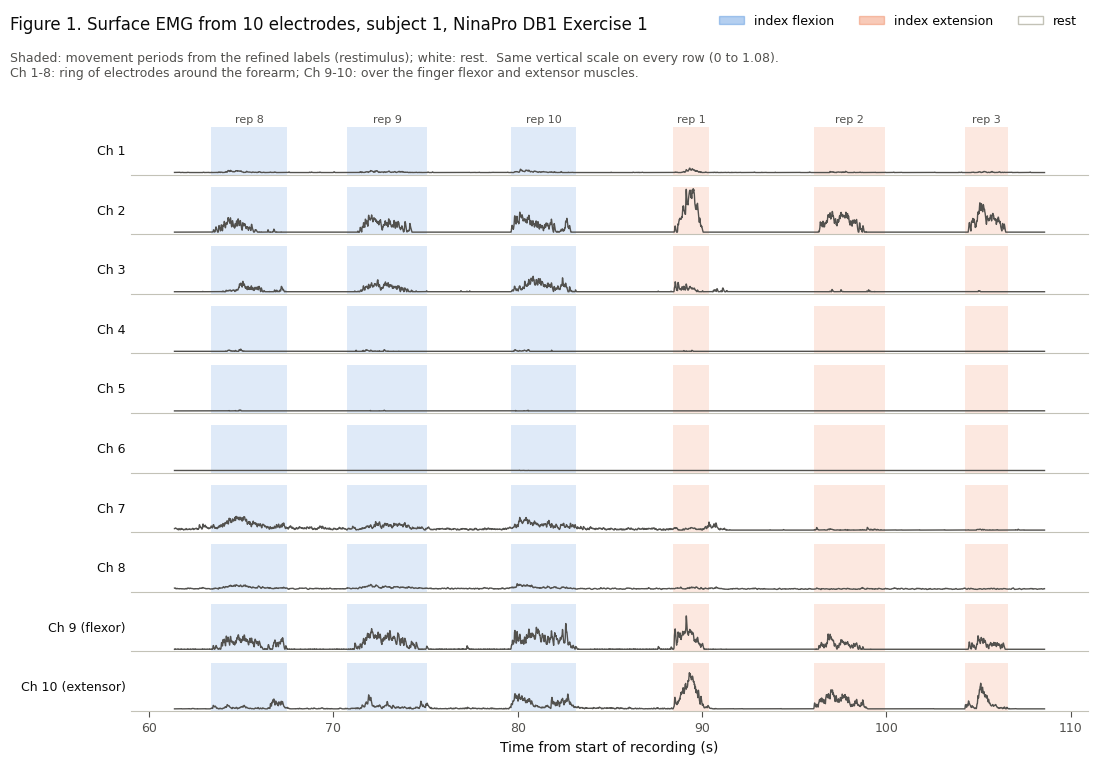

Saved: /content/drive/MyDrive/emg-ninapro/figures/fig1_emg_signal.png


In [5]:
# ============================================================
# 1.2  FIGURE 1: ten EMG channels with movement labels
# ============================================================
# A ~50-second excerpt that crosses from one movement to the next, so you
# can see muscle activity switch on in each labelled period and whether
# a different movement gives a different pattern across the electrodes.

from matplotlib.patches import Patch

FROM = (1, 8)   # start at movement 1 (index flexion), repetition 8
TO = (2, 3)     # stop after movement 2 (index extension), repetition 3
PAD = 2 * FS    # add 2 s of context at each end (2 s x 100 samples/s)

i0 = max(np.flatnonzero((label == FROM[0]) & (rep == FROM[1]))[0] - PAD, 0)
i1 = min(np.flatnonzero((label == TO[0]) & (rep == TO[1]))[-1] + PAD, len(label))
t = np.arange(i0, i1) / FS          # time in seconds from the start of the recording
x, lab, rp = emg[i0:i1], label[i0:i1], rep[i0:i1]

# Colours: one light wash per movement (colour-blind-safe pair), dark grey signal
WASH = {FROM[0]: "#2a78d6", TO[0]: "#eb6834"}          # blue, orange
INK, GREY, AXIS = "#0b0b0b", "#52514e", "#c3c2b7"
CHANNELS = [f"Ch {c}" for c in range(1, 9)] + ["Ch 9 (flexor)", "Ch 10 (extensor)"]

# Where each labelled block starts and stops inside the excerpt
cut = np.flatnonzero(np.diff(lab)) + 1
starts, stops = np.r_[0, cut], np.r_[cut, len(lab)]

fig, axes = plt.subplots(10, 1, figsize=(11, 8), sharex=True, sharey=True)
for ch, ax in enumerate(axes):
    for s, e in zip(starts, stops):
        if lab[s] > 0:                                  # shade movements, leave rest white
            ax.axvspan(t[s], t[e - 1], color=WASH[lab[s]], alpha=0.15, lw=0)
    ax.plot(t, x[:, ch], color=GREY, lw=1)
    ax.set_ylabel(CHANNELS[ch], rotation=0, ha="right", va="center", fontsize=9, color=INK)
    ax.set_yticks([])                                   # same scale on every row (see subtitle)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(axis="x", colors=GREY, labelsize=9,
                   length=4 if ax is axes[-1] else 0)    # tick marks on the bottom row only
axes[-1].set_xlabel("Time from start of recording (s)", color=INK)

# Repetition number above each shaded block in the top row
top = axes[0].get_ylim()[1]
for s, e in zip(starts, stops):
    if lab[s] > 0:
        axes[0].text((t[s] + t[e - 1]) / 2, top * 1.05, f"rep {rp[s]}",
                     ha="center", va="bottom", fontsize=8, color=GREY)

fig.suptitle(f"Figure 1. Surface EMG from 10 electrodes, subject {SUBJECT}, NinaPro DB1 Exercise 1",
             x=0.01, ha="left", fontsize=12, color=INK)
fig.text(0.01, 0.935,
         "Shaded: movement periods from the refined labels (restimulus); white: rest.  "
         f"Same vertical scale on every row (0 to {top:.2f}).\n"
         "Ch 1-8: ring of electrodes around the forearm; Ch 9-10: over the finger flexor and extensor muscles.",
         ha="left", va="top", fontsize=9, color=GREY)
legend = [Patch(color=WASH[k], alpha=0.35, label=MOVEMENTS[k]) for k in WASH]
legend.append(Patch(facecolor="white", edgecolor=AXIS, label="rest"))
fig.legend(handles=legend, loc="upper right", bbox_to_anchor=(0.99, 0.995),
           ncol=3, frameon=False, fontsize=9)
fig.subplots_adjust(top=0.84, hspace=0.25, left=0.12, right=0.99)

FIG1 = FIG_DIR / "fig1_emg_signal.png"
fig.savefig(FIG1, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved:", FIG1)

## 2. Windows and features
   ### 2.1 Cut the signal into windows and compute features

In [6]:
# ============================================================
# 2.1  WINDOWS AND FEATURES for one subject
# ============================================================
# A classifier needs many short labelled examples. We slide a 200 ms window
# along the recording in 50 ms steps and describe each window with
# 4 numbers per electrode (10 electrodes x 4 = 40 features).

from numpy.lib.stride_tricks import sliding_window_view

WIN = 20    # window length: 20 samples = 200 ms at 100 Hz
STEP = 5    # step between windows: 5 samples = 50 ms, so neighbours share 150 ms

def make_windows(emg, label, rep, win=WIN, step=STEP):
    """Cut the recording into overlapping windows and keep only those lying
    entirely inside one repetition of one movement (rest is left out for now).
    Returns the windows (n, channels, win) and each window's label,
    repetition and first sample."""
    first = np.arange(0, len(label) - win + 1, step)        # first sample of every window
    W = sliding_window_view(emg, win, axis=0)[first]         # (n, channels, win)
    L = sliding_window_view(label, win)[first]               # labels inside each window
    R = sliding_window_view(rep, win)[first]                 # repetitions inside each window
    pure = (L.min(1) == L.max(1)) & (R.min(1) == R.max(1))  # one label and one repetition only
    keep = pure & (L[:, 0] > 0)                              # ...and not rest
    return W[keep], L[keep, 0], R[keep, 0], first[keep]

def extract_features(W):
    """Four features per channel for windows W of shape (n, channels, win).
    Returns an (n, 4 x channels) array: all MAV columns, then RMS, WL and SD."""
    mav = np.mean(np.abs(W), axis=2)                  # mean absolute value: average level
    rms = np.sqrt(np.mean(W ** 2, axis=2))            # root mean square: signal energy
    wl = np.sum(np.abs(np.diff(W, axis=2)), axis=2)   # waveform length: how much it changes
    sd = np.std(W, axis=2)                            # standard deviation: spread
    return np.hstack([mav, rms, wl, sd])

FEATURE_NAMES = [f"{f} ch{c}" for f in ("MAV", "RMS", "WL", "SD") for c in range(1, 11)]

W, y, r, wfirst = make_windows(emg, label, rep)
F = extract_features(W)
print("Windows:", W.shape, "->  features:", F.shape)
print("Any missing feature values?", bool(np.isnan(F).any()))
print("Windows per movement 1-12:   ", np.bincount(y, minlength=13)[1:].tolist())
print("Windows per repetition 1-10: ", np.bincount(r, minlength=11)[1:].tolist())

# Does every electrode pick something up? Compare its average level during
# rest with its average level (MAV) during the movement it responds to most.
by_move = pd.DataFrame(F[:, :10], columns=CHANNELS).groupby(y).mean()   # 12 movements x 10 electrodes
check = pd.DataFrame({"rest level": emg[label == 0].mean(axis=0),
                      "most active in": [MOVEMENTS[k] for k in by_move.idxmax()],
                      "level there": by_move.max().values}, index=CHANNELS)
check["times rest"] = check["level there"] / check["rest level"].clip(lower=1e-4)
print(f"\nElectrode activity, subject {SUBJECT} (same units as Figure 1):")
print(check.round(3).to_string())

Windows: (7087, 10, 20) ->  features: (7087, 40)
Any missing feature values? False
Windows per movement 1-12:    [729, 484, 789, 557, 755, 574, 486, 561, 483, 599, 460, 610]
Windows per repetition 1-10:  [708, 727, 676, 668, 785, 680, 665, 778, 718, 682]

Electrode activity, subject 1 (same units as Figure 1):
                  rest level         most active in  level there  times rest
Ch 1                   0.008  little finger flexion        0.605      73.165
Ch 2                   0.003        thumb adduction        0.704     272.541
Ch 3                   0.004       middle extension        0.277      64.145
Ch 4                   0.003  little finger flexion        0.083      30.401
Ch 5                   0.002       middle extension        0.029      11.479
Ch 6                   0.002       middle extension        0.076      31.288
Ch 7                   0.059       middle extension        1.663      28.301
Ch 8                   0.056        thumb adduction        0.613      10

### 2.2 Why we split by repetition

In [7]:
# ============================================================
# 2.2  WHY WE SPLIT BY REPETITION: measuring the overlap leak
# ============================================================
# Benchmark split (Atzori et al. 2014): train on repetitions 1,3,4,6,8,9,10;
# test on 2,5,7. Here we count how often a test window shares raw samples
# with a training window - under this split and under a random split.

TRAIN_REPS = [1, 3, 4, 6, 8, 9, 10]
TEST_REPS = [2, 5, 7]

def shares_samples(test_first, train_first, win=WIN):
    """For each test window: does any training window share at least one sample?
    Two windows overlap when their first samples are less than `win` apart."""
    train_sorted = np.sort(train_first)
    pos = np.searchsorted(train_sorted, test_first)                     # where each test window slots in
    before = train_sorted[np.clip(pos - 1, 0, len(train_sorted) - 1)]   # nearest training window before it
    after = train_sorted[np.clip(pos, 0, len(train_sorted) - 1)]        # nearest training window after it
    gap = np.minimum(np.abs(test_first - before), np.abs(after - test_first))
    return gap < win

# 1) The right way: whole repetitions are held out
is_test = np.isin(r, TEST_REPS)
leak_rep = shares_samples(wfirst[is_test], wfirst[~is_test]).mean()

# 2) The wrong way: the same number of test windows, picked at random
rng = np.random.default_rng(SEED)
is_test_random = np.zeros(len(y), dtype=bool)
is_test_random[rng.choice(len(y), size=is_test.sum(), replace=False)] = True
leak_random = shares_samples(wfirst[is_test_random], wfirst[~is_test_random]).mean()

print(f"Training windows: {(~is_test).sum()}, test windows: {is_test.sum()} ({is_test.mean():.0%} test)")
print("Test windows that share samples with a training window:")
print(f"  split by repetition: {leak_rep:.1%}")
print(f"  random split:        {leak_random:.1%}")

Training windows: 4910, test windows: 2177 (31% test)
Test windows that share samples with a training window:
  split by repetition: 0.0%
  random split:        99.6%


## 3. One subject, three models
   ### 3.1 Train on repetitions 1, 3, 4, 6, 8, 9, 10; test on 2, 5, 7

In [8]:
# ============================================================
# 3.1  ONE SUBJECT, THREE MODELS (plus a baseline)
# ============================================================
# Train on repetitions 1,3,4,6,8,9,10 and test on 2,5,7.
# Each model is a Pipeline: the scaler learns its means and SDs from the
# training windows only, so nothing about the test windows leaks in.

import time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

def make_models():
    """Fresh, untrained copies of the three models, each with its own scaler.
    (Trees don't need scaling; it is kept so all three share one recipe.)"""
    return {
        "LDA": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
        "SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")),
        "Random forest": make_pipeline(StandardScaler(), RandomForestClassifier(
            n_estimators=300, random_state=SEED, n_jobs=-1)),
    }

X_train, y_train = F[~is_test], y[~is_test]   # training repetitions
X_test, y_test = F[is_test], y[is_test]       # held-out repetitions

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Chance level (1 in 12):                     {1 / 12:.1%}")
print(f"Baseline (always guess the most common one): {accuracy_score(y_test, baseline.predict(X_test)):.1%}\n")

predictions, rows = {}, []
for name, model in make_models().items():
    t0 = time.perf_counter()
    model.fit(X_train, y_train)                   # learn from the training windows
    t1 = time.perf_counter()
    pred = model.predict(X_test)                  # predict every test window
    t2 = time.perf_counter()
    predictions[name] = pred
    rows.append({"model": name,
                 "test accuracy (%)": 100 * accuracy_score(y_test, pred),
                 "training time (s)": t1 - t0,
                 # microseconds (millionths of a second) per window, timed on all test
                 # windows at once; one window at a time in real use would be slower
                 "prediction (µs per window)": 1e6 * (t2 - t1) / len(y_test)})

scores = pd.DataFrame(rows).set_index("model")
print(scores.round({"test accuracy (%)": 1, "training time (s)": 2,
                    "prediction (µs per window)": 1}).to_string())

Chance level (1 in 12):                     8.3%
Baseline (always guess the most common one): 9.1%

               test accuracy (%)  training time (s)  prediction (µs per window)
model                                                                          
LDA                         68.1               0.12                         9.0
SVM                         78.3               3.02                       950.9
Random forest               80.6              13.07                        59.3


### 3.2 Which movements get confused?

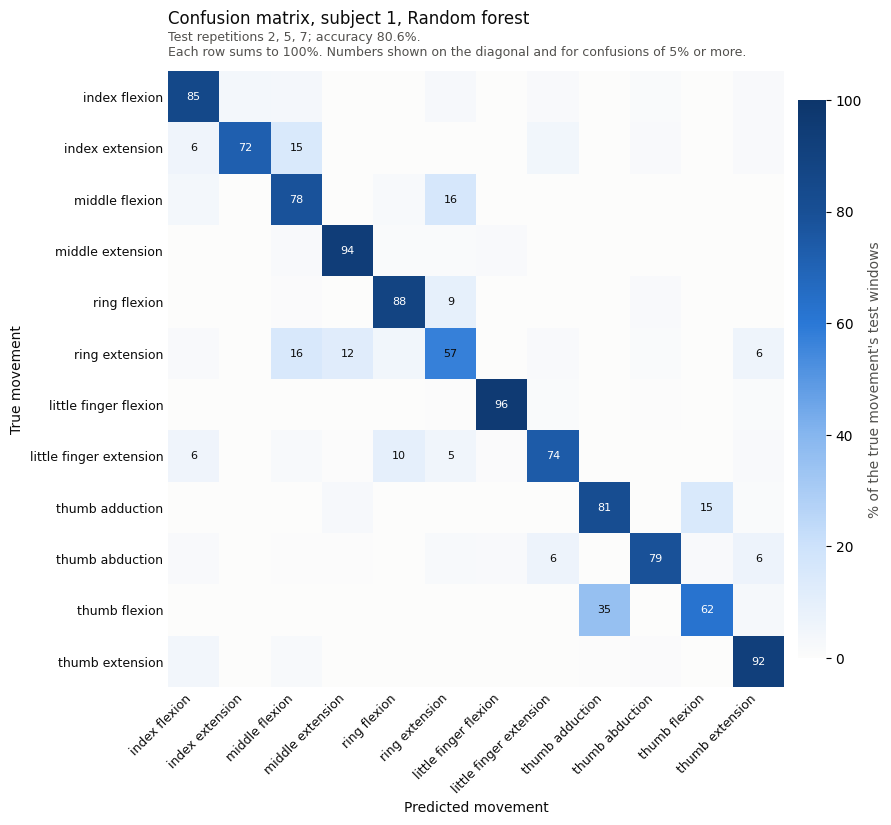

Recognised correctly, per movement (% of its test windows):
ring extension             57.1
thumb flexion              61.8
index extension            71.8
little finger extension    74.1
middle flexion             78.3
thumb abduction            78.7
thumb adduction            81.5
index flexion              85.5
ring flexion               88.4
thumb extension            92.2
middle extension           93.7
little finger flexion      95.7

Most common confusions (true -> predicted):
  thumb flexion -> thumb adduction: 35.3%
  middle flexion -> ring extension: 16.2%
  ring extension -> middle flexion: 15.5%
  index extension -> middle flexion: 14.7%
  thumb adduction -> thumb flexion: 14.6%


In [9]:
# ============================================================
# 3.2  CONFUSION MATRIX: which movements get mixed up?
# ============================================================
# Rows = the movement the person actually made; columns = the model's guess.
# Each row is converted to percentages, so the diagonal is the share of each
# movement's test windows that were recognised correctly.

from sklearn.metrics import confusion_matrix
from matplotlib.colors import LinearSegmentedColormap

NAMES = MOVEMENTS[1:]                     # the 12 movement names, labels 1-12
# One-hue sequential scale: near-white = 0%, dark blue = 100%
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])

def plot_confusion(cm_pct, title, subtitle, path):
    """Draw a row-normalised confusion matrix and save it as a PNG.
    Numbers are shown on the diagonal and for confusions of 5% or more."""
    n = len(NAMES)
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(cm_pct, cmap=BLUES, vmin=0, vmax=100)
    for i in range(n):
        for j in range(n):
            v = cm_pct[i, j]
            if i == j or v >= 5:
                ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                        color="white" if v >= 60 else INK)   # white text on dark cells
    ax.set_xticks(range(n), NAMES, rotation=45, ha="right", fontsize=9)
    ax.set_yticks(range(n), NAMES, fontsize=9)
    ax.set_xlabel("Predicted movement", color=INK)
    ax.set_ylabel("True movement", color=INK)
    ax.tick_params(length=0, colors=INK)
    for spine in ax.spines.values():
        spine.set_visible(False)
    cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    cbar.set_label("% of the true movement's test windows", color=GREY)
    cbar.outline.set_visible(False)
    ax.set_title(title, loc="left", fontsize=12, color=INK, pad=34)
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9, color=GREY, va="bottom")
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

best = scores["test accuracy (%)"].idxmax()            # this subject's most accurate model
cm = confusion_matrix(y_test, predictions[best], labels=range(1, 13))
cm_pct = 100 * cm / cm.sum(axis=1, keepdims=True)      # each row as % of that movement

plot_confusion(
    cm_pct,
    title=f"Confusion matrix, subject {SUBJECT}, {best}",
    subtitle=(f"Test repetitions 2, 5, 7; accuracy {scores.loc[best, 'test accuracy (%)']:.1f}%.\n"
              "Each row sums to 100%. Numbers shown on the diagonal and for confusions of 5% or more."),
    path=FIG_DIR / f"confusion_subject{SUBJECT}.png")

# The same information as text
recall = pd.Series(np.diag(cm_pct), index=NAMES).sort_values()
print("Recognised correctly, per movement (% of its test windows):")
print(recall.round(1).to_string())
pairs = [(cm_pct[i, j], NAMES[i], NAMES[j]) for i in range(12) for j in range(12) if i != j]
print("\nMost common confusions (true -> predicted):")
for v, true_name, pred_name in sorted(pairs, reverse=True)[:5]:
    print(f"  {true_name} -> {pred_name}: {v:.1f}%")

 ## 4. All 27 subjects
   ### 4.1 One set of models per person

In [10]:
# ============================================================
# 4.1  ALL 27 SUBJECTS: the same recipe, one set of models per person
# ============================================================
# About 8 minutes on free Colab. Results are saved to Drive, so later
# sessions can reload them instead of recomputing (set RERUN = True to
# recompute, e.g. after changing any code above).

RESULTS_DIR = PROJECT_DIR / "results"          # our own outputs (fine to publish)
RESULTS_DIR.mkdir(exist_ok=True)
ACC_FILE = RESULTS_DIR / "accuracy_per_subject.csv"
CM_FILE = RESULTS_DIR / "confusion_counts.npz"
RERUN = False
MODEL_NAMES = list(make_models())               # ["LDA", "SVM", "Random forest"]

def missing_repetitions(label, rep):
    """Movements that do NOT have exactly repetitions 1-10 (should be none)."""
    return [k for k in range(1, 13) if set(np.unique(rep[label == k])) != set(range(1, 11))]

if ACC_FILE.exists() and CM_FILE.exists() and not RERUN:
    acc = pd.read_csv(ACC_FILE, index_col="subject")
    cm_sum = dict(np.load(CM_FILE))
    print("Loaded saved results from", ACC_FILE)
else:
    rows = []
    cm_sum = {m: np.zeros((12, 12), dtype=int) for m in MODEL_NAMES}   # summed over subjects
    for n in SUBJECTS:
        t_start = time.perf_counter()
        emg_n, label_n, rep_n = load_subject(n)
        bad = missing_repetitions(label_n, rep_n)
        if bad:
            print(f"   WARNING S{n}: movements {bad} do not have repetitions 1-10")
        W_n, y_n, r_n, _ = make_windows(emg_n, label_n, rep_n)
        F_n = extract_features(W_n)
        test_n = np.isin(r_n, TEST_REPS)                  # repetitions 2, 5, 7
        row = {"subject": n, "windows": len(y_n)}
        for name, model in make_models().items():         # fresh, untrained models
            model.fit(F_n[~test_n], y_n[~test_n])
            pred = model.predict(F_n[test_n])
            row[name] = 100 * accuracy_score(y_n[test_n], pred)
            cm_sum[name] += confusion_matrix(y_n[test_n], pred, labels=range(1, 13))
        rows.append(row)
        print(f"S{n:>2}:  " + "   ".join(f"{m} {row[m]:5.1f}" for m in MODEL_NAMES)
              + f"   ({time.perf_counter() - t_start:.0f} s)")
    acc = pd.DataFrame(rows).set_index("subject")
    acc.to_csv(ACC_FILE)                                  # save for later sessions
    np.savez(CM_FILE, **cm_sum)

summary = acc[MODEL_NAMES].agg(["mean", "std", "min", "max"]).T   # std = SD across the 27 subjects
print("\nTest accuracy across all 27 subjects (%):")
print(summary.round(1).to_string())
print("\nResults table (mean ± SD):")
for m in MODEL_NAMES:
    print(f"  {m:<14} {summary.loc[m, 'mean']:.1f} ± {summary.loc[m, 'std']:.1f}%")
wins = acc[MODEL_NAMES].idxmax(axis=1).value_counts()      # which model won for each person
print("\nMost accurate model, counted over subjects:", wins.to_dict())

S 1:  LDA  68.1   SVM  78.3   Random forest  80.6   (13 s)
S 2:  LDA  70.8   SVM  77.0   Random forest  79.8   (13 s)
S 3:  LDA  73.5   SVM  83.5   Random forest  88.2   (8 s)
S 4:  LDA  69.7   SVM  74.2   Random forest  75.5   (13 s)
S 5:  LDA  68.8   SVM  76.2   Random forest  79.8   (18 s)
S 6:  LDA  69.8   SVM  78.1   Random forest  80.0   (16 s)
S 7:  LDA  80.1   SVM  88.9   Random forest  90.9   (11 s)
S 8:  LDA  76.3   SVM  86.6   Random forest  86.5   (10 s)
S 9:  LDA  72.3   SVM  82.1   Random forest  85.6   (10 s)
S10:  LDA  74.4   SVM  83.4   Random forest  84.6   (13 s)
S11:  LDA  74.2   SVM  87.3   Random forest  86.4   (15 s)
S12:  LDA  70.8   SVM  81.3   Random forest  84.7   (14 s)
S13:  LDA  79.2   SVM  84.7   Random forest  82.8   (7 s)
S14:  LDA  66.8   SVM  74.5   Random forest  76.1   (16 s)
S15:  LDA  79.6   SVM  85.5   Random forest  84.6   (14 s)
S16:  LDA  73.0   SVM  75.9   Random forest  71.9   (12 s)
S17:  LDA  77.2   SVM  84.0   Random forest  89.0   (9 s)


### 4.2 Figure 3: accuracy per model across subjects

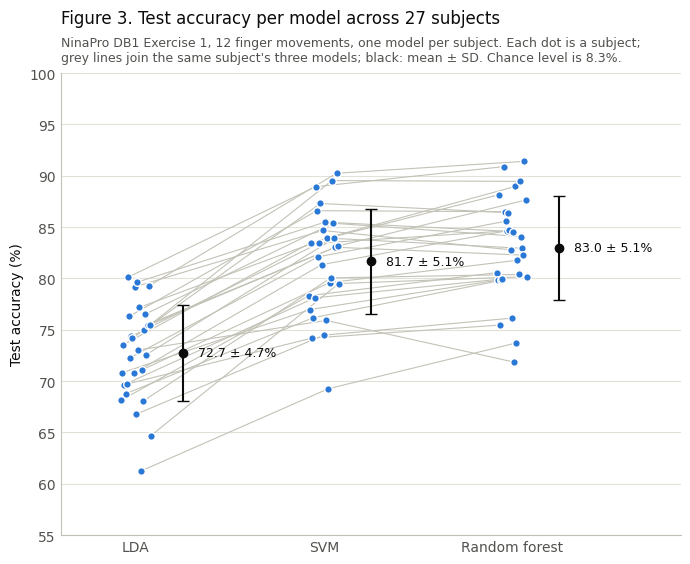

Saved: /content/drive/MyDrive/emg-ninapro/figures/fig3_accuracy_per_model.png

Paired comparison across subjects (difference in percentage points):
  Random forest minus SVM: mean +1.3 (SD 2.3); Random forest better for 18 of 27 subjects; Wilcoxon p = 0.007
  Random forest minus LDA: mean +10.3 (SD 3.7); Random forest better for 26 of 27 subjects; Wilcoxon p = 3e-08
  SVM minus LDA: mean +8.9 (SD 2.8); SVM better for 27 of 27 subjects; Wilcoxon p = 1.5e-08


In [11]:
# ============================================================
# 4.2  FIGURE 3: accuracy per model across the 27 subjects
# ============================================================
# Every person was tested with all three models, so we compare models
# WITHIN each person (a paired comparison), not just their averages.

from scipy.stats import wilcoxon

BLUE = "#2a78d6"
xs = np.arange(len(MODEL_NAMES))                      # x positions: 0, 1, 2
offset = np.linspace(-0.08, 0.08, len(acc))           # small sideways spread so dots don't hide each other

fig, ax = plt.subplots(figsize=(8, 6))
for k, (_, row) in enumerate(acc[MODEL_NAMES].iterrows()):
    ax.plot(xs + offset[k], row.values, color=AXIS, lw=0.8, zorder=1)        # one grey line per person
    ax.scatter(xs + offset[k], row.values, s=30, color=BLUE,
               edgecolor="white", linewidth=1, zorder=2)                     # one dot per person and model
for i, m in enumerate(MODEL_NAMES):
    mean, sd = acc[m].mean(), acc[m].std()
    ax.errorbar(xs[i] + 0.25, mean, yerr=sd, fmt="o", color=INK, ms=6,
                capsize=4, lw=1.5, zorder=3)                                 # mean ± SD
    ax.text(xs[i] + 0.33, mean, f"{mean:.1f} ± {sd:.1f}%", va="center", fontsize=9, color=INK)

low = 5 * np.floor((acc[MODEL_NAMES].min().min() - 3) / 5)                  # round the axis start down to a multiple of 5
ax.set_ylim(low, 100)
ax.set_xlim(-0.4, len(MODEL_NAMES) - 0.1)
ax.set_xticks(xs, MODEL_NAMES, fontsize=10, color=INK)
ax.set_ylabel("Test accuracy (%)", color=INK)
ax.yaxis.grid(True, color="#e1e0d9", lw=0.8)                                # hairline gridlines
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(AXIS)
ax.tick_params(colors=GREY, length=0)
ax.set_title("Figure 3. Test accuracy per model across 27 subjects",
             loc="left", fontsize=12, color=INK, pad=36)
ax.text(0, 1.02, "NinaPro DB1 Exercise 1, 12 finger movements, one model per subject. Each dot is a subject;\n"
                 "grey lines join the same subject's three models; black: mean ± SD. Chance level is 8.3%.",
        transform=ax.transAxes, fontsize=9, color=GREY, va="bottom")
FIG3 = FIG_DIR / "fig3_accuracy_per_model.png"
fig.savefig(FIG3, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved:", FIG3)

# Paired comparison: for each person, how much better is one model than another?
# Wilcoxon signed-rank test: are the 27 differences consistently on one side of zero?
# A small p-value means a difference this consistent is unlikely if the models were equally good.
# We make three comparisons, so use the stricter threshold 0.05 / 3 = 0.017.
print("\nPaired comparison across subjects (difference in percentage points):")
for a, b in [("Random forest", "SVM"), ("Random forest", "LDA"), ("SVM", "LDA")]:
    d = acc[a] - acc[b]
    p = wilcoxon(acc[a], acc[b]).pvalue
    print(f"  {a} minus {b}: mean {d.mean():+.1f} (SD {d.std():.1f}); "
          f"{a} better for {(d > 0).sum()} of {len(d)} subjects; Wilcoxon p = {p:.2g}")

### 4.3 Figure 2: which movements get confused, across all subjects

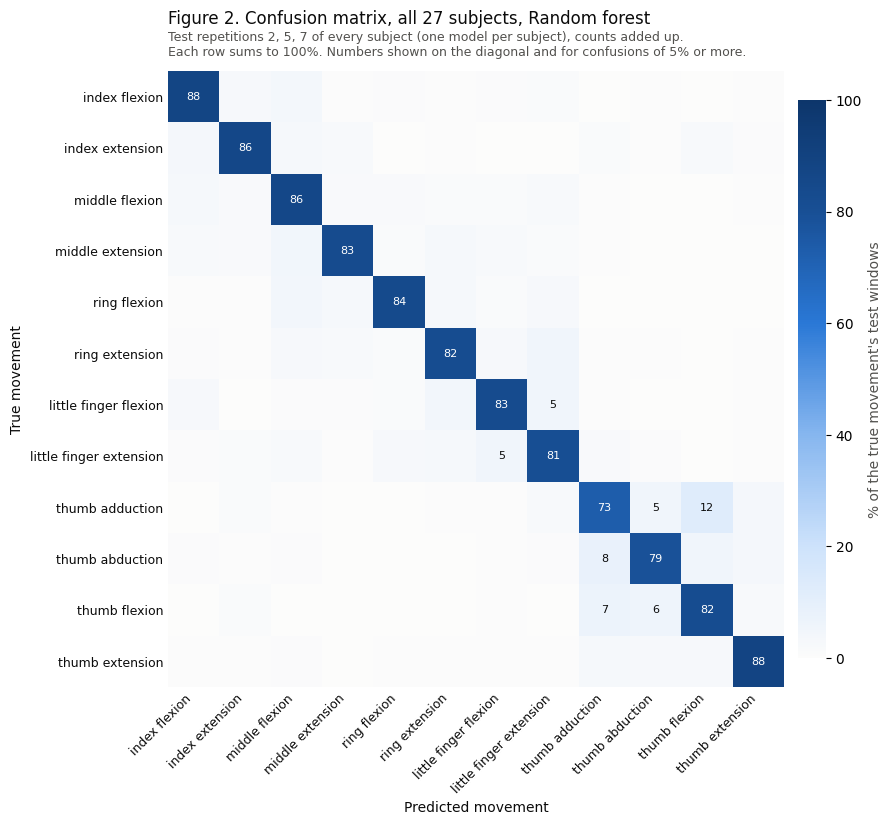

Recognised correctly, per movement, all subjects (Random forest):
thumb adduction            72.8
thumb abduction            78.5
little finger extension    80.8
thumb flexion              81.8
ring extension             82.4
little finger flexion      82.9
middle extension           83.1
ring flexion               83.8
middle flexion             85.7
index extension            85.7
index flexion              87.7
thumb extension            88.0

Most common confusions, all subjects (true -> predicted):
  thumb adduction -> thumb flexion: 12.3%
  thumb abduction -> thumb adduction: 8.0%
  thumb flexion -> thumb adduction: 7.0%
  thumb flexion -> thumb abduction: 5.9%
  little finger extension -> little finger flexion: 5.4%
  little finger flexion -> little finger extension: 5.4%
  thumb adduction -> thumb abduction: 5.3%
  thumb abduction -> thumb flexion: 5.0%


In [12]:
# ============================================================
# 4.3  FIGURE 2: confusion matrix for all 27 subjects combined
# ============================================================
# Add up every subject's test-set confusion counts (saved in 4.1), then show
# each row as percentages, as in 3.2. Do subject 1's patterns hold overall?

best_overall = summary["mean"].idxmax()               # highest mean accuracy across subjects
cm_all = cm_sum[best_overall]
cm_all_pct = 100 * cm_all / cm_all.sum(axis=1, keepdims=True)

plot_confusion(
    cm_all_pct,
    title=f"Figure 2. Confusion matrix, all 27 subjects, {best_overall}",
    subtitle=("Test repetitions 2, 5, 7 of every subject (one model per subject), counts added up.\n"
              "Each row sums to 100%. Numbers shown on the diagonal and for confusions of 5% or more."),
    path=FIG_DIR / "fig2_confusion_all_subjects.png")

# The same information as text
recall_all = pd.Series(np.diag(cm_all_pct), index=NAMES).sort_values()
print(f"Recognised correctly, per movement, all subjects ({best_overall}):")
print(recall_all.round(1).to_string())
pairs_all = [(cm_all_pct[i, j], NAMES[i], NAMES[j]) for i in range(12) for j in range(12) if i != j]
print("\nMost common confusions, all subjects (true -> predicted):")
for v, true_name, pred_name in sorted(pairs_all, reverse=True)[:8]:
    print(f"  {true_name} -> {pred_name}: {v:.1f}%")

## 5. How many electrodes do we need?
   ### 5.1 Remove electrodes one at a time

In [13]:
# ============================================================
# 5.1  ELECTRODE EXPERIMENT: remove electrodes one at a time
# ============================================================
# For each subject: train a random forest on all 10 electrodes (training
# repetitions only), drop the electrode it relied on LEAST, retrain, and repeat
# down to 1 electrode, testing on repetitions 2, 5, 7 at every step.
# For comparison, electrodes are also removed in a random order.
# The choice of electrode never looks at the test repetitions.
#
# To keep the run to about 20-30 minutes this uses 100 trees instead of 300
# (compare its 10-electrode accuracy with Milestone 4). Progress is saved after
# every subject: if Colab disconnects, run the cell again and it carries on.

ELEC_FILE = RESULTS_DIR / "electrode_experiment.csv"
ORDER_FILE = RESULTS_DIR / "electrode_removal_order.csv"
RERUN_ELECTRODES = False                       # True = delete saved results and start again
if RERUN_ELECTRODES:
    ELEC_FILE.unlink(missing_ok=True)
    ORDER_FILE.unlink(missing_ok=True)

def forest_100():
    return make_pipeline(StandardScaler(), RandomForestClassifier(
        n_estimators=100, random_state=SEED, n_jobs=-1))

def columns_for(electrodes):
    """Feature columns (MAV, RMS, WL, SD) of the given electrodes, numbered 0-9."""
    return [f * 10 + e for f in range(4) for e in electrodes]

def fit_and_test(F, y, test, electrodes):
    """Train on training windows using only these electrodes. Return the test
    accuracy (%) and each electrode's importance (learned from training data)."""
    cols = columns_for(electrodes)
    model = forest_100().fit(F[~test][:, cols], y[~test])
    accuracy = 100 * accuracy_score(y[test], model.predict(F[test][:, cols]))
    importance = model[-1].feature_importances_.reshape(4, len(electrodes)).sum(axis=0)
    return accuracy, importance

rng = np.random.default_rng(SEED)
random_order = {n: rng.permutation(10) for n in SUBJECTS}     # one fixed random order per subject
done = set(pd.read_csv(ELEC_FILE)["subject"]) if ELEC_FILE.exists() else set()

for n in SUBJECTS:
    if n in done:
        continue                                              # finished in an earlier run
    t_start = time.perf_counter()
    emg_n, label_n, rep_n = load_subject(n)
    W_n, y_n, r_n, _ = make_windows(emg_n, label_n, rep_n)
    F_n = extract_features(W_n)
    test_n = np.isin(r_n, TEST_REPS)

    rows, removed, kept = [], [], list(range(10))             # electrodes 0-9 = Ch 1-10
    while kept:                                               # 1) least important first
        acc_k, importance = fit_and_test(F_n, y_n, test_n, kept)
        rows.append({"subject": n, "order": "least important first",
                     "electrodes": len(kept), "accuracy": acc_k})
        weakest = kept[int(np.argmin(importance))]            # chosen from training data only
        removed.append(weakest)
        kept.remove(weakest)
    rows.append({"subject": n, "order": "random", "electrodes": 10, "accuracy": rows[0]["accuracy"]})
    for k in range(9, 0, -1):                                 # 2) random order
        acc_k, _ = fit_and_test(F_n, y_n, test_n, list(random_order[n][:k]))
        rows.append({"subject": n, "order": "random", "electrodes": k, "accuracy": acc_k})

    pd.DataFrame([[n] + [e + 1 for e in removed]],
                 columns=["subject"] + [f"removed_{i}" for i in range(1, 11)]
                 ).to_csv(ORDER_FILE, mode="a", header=not ORDER_FILE.exists(), index=False)
    pd.DataFrame(rows).to_csv(ELEC_FILE, mode="a", header=not ELEC_FILE.exists(), index=False)
    a = {r["electrodes"]: r["accuracy"] for r in rows if r["order"] == "least important first"}
    print(f"S{n:>2}: 10 el {a[10]:.1f} | 5 el {a[5]:.1f} | 2 el {a[2]:.1f} | 1 el {a[1]:.1f}"
          f" | removal order (last = most useful): {[e + 1 for e in removed]}"
          f"  ({time.perf_counter() - t_start:.0f} s)")

elec = pd.read_csv(ELEC_FILE).drop_duplicates(["subject", "order", "electrodes"], keep="last")
print(f"\nSubjects finished: {elec['subject'].nunique()} of 27")

S 1: 10 el 80.6 | 5 el 75.2 | 2 el 55.0 | 1 el 31.3 | removal order (last = most useful): [5, 6, 4, 3, 9, 2, 1, 10, 7, 8]  (42 s)
S 2: 10 el 79.8 | 5 el 73.1 | 2 el 40.6 | 1 el 21.6 | removal order (last = most useful): [7, 6, 2, 9, 5, 10, 8, 4, 1, 3]  (51 s)
S 3: 10 el 87.7 | 5 el 82.0 | 2 el 51.6 | 1 el 27.3 | removal order (last = most useful): [5, 6, 4, 2, 1, 7, 9, 3, 10, 8]  (41 s)
S 4: 10 el 75.6 | 5 el 72.7 | 2 el 49.9 | 1 el 22.6 | removal order (last = most useful): [5, 9, 6, 4, 2, 10, 8, 3, 7, 1]  (53 s)
S 5: 10 el 80.2 | 5 el 72.8 | 2 el 41.2 | 1 el 20.7 | removal order (last = most useful): [1, 6, 5, 9, 8, 2, 7, 4, 3, 10]  (74 s)
S 6: 10 el 79.3 | 5 el 71.4 | 2 el 44.5 | 1 el 25.9 | removal order (last = most useful): [1, 5, 6, 3, 2, 10, 4, 8, 7, 9]  (61 s)
S 7: 10 el 90.4 | 5 el 87.7 | 2 el 73.9 | 1 el 58.7 | removal order (last = most useful): [1, 4, 3, 5, 7, 8, 2, 6, 9, 10]  (42 s)
S 8: 10 el 86.2 | 5 el 80.2 | 2 el 57.0 | 1 el 24.0 | removal order (last = most useful): 

### 5.2 Figure 4: accuracy against number of electrodes

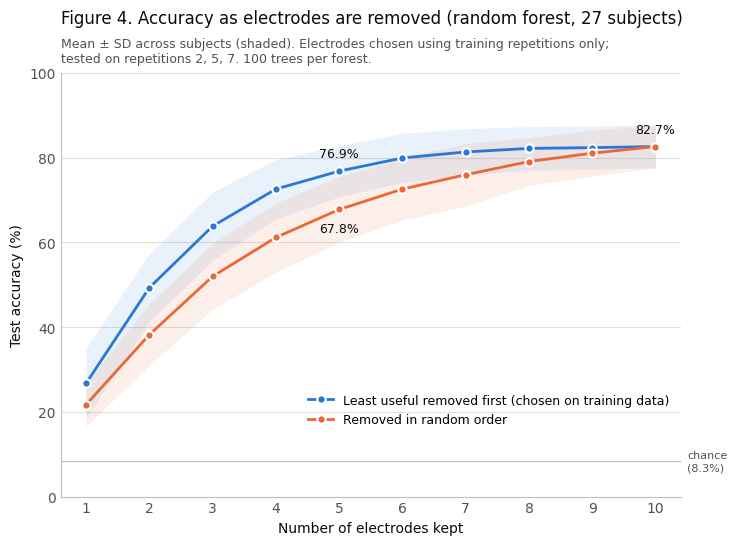

Saved: /content/drive/MyDrive/emg-ninapro/figures/fig4_accuracy_vs_electrodes.png

Test accuracy by number of electrodes kept (mean ± SD over 27 subjects, %):
  kept   least useful removed first   random order   difference
    10         82.7 ±  5.0              82.7 ±  5.0       +0.0
     9         82.4 ±  5.1              81.1 ±  5.4       +1.3
     8         82.2 ±  5.1              79.1 ±  5.6       +3.1
     7         81.4 ±  5.5              76.0 ±  7.4       +5.4
     6         80.0 ±  5.8              72.6 ±  7.3       +7.4
     5         76.9 ±  6.1              67.8 ±  7.8       +9.1
     4         72.6 ±  7.0              61.2 ±  8.1      +11.4
     3         63.9 ±  8.1              52.0 ±  7.8      +11.9
     2         49.3 ±  8.0              38.2 ±  7.2      +11.1
     1         26.8 ±  8.2              21.7 ±  5.2       +5.0

All 10 electrodes: 82.7% with 100 trees vs 83.0% with 300 trees (Milestone 4)

Electrode usefulness across 27 subjects (counts are numbers of subj

In [14]:
# ============================================================
# 5.2  FIGURE 4: accuracy against the number of electrodes
# ============================================================
ORANGE = "#eb6834"
ORDERS = {"least important first": ("Least useful removed first (chosen on training data)", BLUE),
          "random": ("Removed in random order", ORANGE)}
curve = elec.groupby(["order", "electrodes"])["accuracy"].agg(["mean", "std"])   # mean and SD over subjects

fig, ax = plt.subplots(figsize=(8, 5.5))
for order, (name, colour) in ORDERS.items():
    c = curve.loc[order]
    ax.fill_between(c.index, c["mean"] - c["std"], c["mean"] + c["std"],
                    color=colour, alpha=0.10, lw=0)                         # ± SD band
    ax.plot(c.index, c["mean"], color=colour, lw=2, marker="o", ms=6,
            markeredgecolor="white", markeredgewidth=1.5, label=name)       # mean
ax.axhline(100 / 12, color=AXIS, lw=1)
ax.text(10.5, 100 / 12, "chance\n(8.3%)", va="center", fontsize=8, color=GREY)

# Label only the numbers the story is about: all 10 electrodes vs 5
best5, rand5 = curve.loc[("least important first", 5), "mean"], curve.loc[("random", 5), "mean"]
all10 = curve.loc[("least important first", 10), "mean"]
ax.annotate(f"{all10:.1f}%", (10, all10), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9, color=INK)
ax.annotate(f"{best5:.1f}%", (5, best5), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9, color=INK)
ax.annotate(f"{rand5:.1f}%", (5, rand5), xytext=(0, -16), textcoords="offset points", ha="center", fontsize=9, color=INK)

ax.set_xticks(range(1, 11))
ax.set_xlim(0.6, 10.4)
ax.set_ylim(0, 100)
ax.set_xlabel("Number of electrodes kept", color=INK)
ax.set_ylabel("Test accuracy (%)", color=INK)
ax.yaxis.grid(True, color="#e1e0d9", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(AXIS)
ax.tick_params(colors=GREY, length=0)
ax.legend(loc="lower right", bbox_to_anchor=(1, 0.14), frameon=False, fontsize=9)   # sits above the chance line
ax.set_title("Figure 4. Accuracy as electrodes are removed (random forest, 27 subjects)",
             loc="left", fontsize=12, color=INK, pad=36)
ax.text(0, 1.02, "Mean ± SD across subjects (shaded). Electrodes chosen using training repetitions only;\n"
                 "tested on repetitions 2, 5, 7. 100 trees per forest.",
        transform=ax.transAxes, fontsize=9, color=GREY, va="bottom")
FIG4 = FIG_DIR / "fig4_accuracy_vs_electrodes.png"
fig.savefig(FIG4, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved:", FIG4)

# --- The same as a table
print("\nTest accuracy by number of electrodes kept (mean ± SD over 27 subjects, %):")
print("  kept   least useful removed first   random order   difference")
for k in range(10, 0, -1):
    m1, s1 = curve.loc[("least important first", k)]
    m2, s2 = curve.loc[("random", k)]
    print(f"  {k:>4}        {m1:5.1f} ± {s1:4.1f}             {m2:5.1f} ± {s2:4.1f}      {m1 - m2:+5.1f}")
print(f"\nAll 10 electrodes: {all10:.1f}% with 100 trees vs "
      f"{acc['Random forest'].mean():.1f}% with 300 trees (Milestone 4)")

# --- Which electrodes matter? Position at which each was removed:
#     1 = removed first (least useful) ... 10 = the last one kept (most useful)
order_df = pd.read_csv(ORDER_FILE).drop_duplicates("subject", keep="last")
pos = np.array([[list(row[1:]).index(ch) + 1 for ch in range(1, 11)] for row in order_df.values])
useful = pd.DataFrame({"mean position (10 = kept last)": pos.mean(axis=0),
                       "removed first": (pos == 1).sum(axis=0),
                       "among last 3 kept": (pos >= 8).sum(axis=0)}, index=CHANNELS)
print("\nElectrode usefulness across 27 subjects (counts are numbers of subjects):")
print(useful.sort_values("mean position (10 = kept last)").round(1).to_string())

 ## Extension: adding rest back in
   ### E.1 Thirteen classes, with and without class balancing

In [15]:
# ============================================================
# E.1  EXTENSION: add rest back in (13 classes)
# ============================================================
# A prosthesis must also recognise "do nothing". Rest dominates the recording,
# so plain accuracy is misleading. We report balanced accuracy (the average of
# the 13 per-class accuracies) and the two errors a user would feel:
# rest misread as a movement (the hand moves on its own) and a movement misread
# as rest (the hand ignores the user). Random forest with 100 trees, as in
# Milestone 5; about 10-15 minutes, saved after every subject.

from sklearn.metrics import balanced_accuracy_score

REST_FILE = RESULTS_DIR / "rest_extension.csv"
RERUN_REST = False                               # True = delete saved results and start again
if RERUN_REST:
    REST_FILE.unlink(missing_ok=True)

def rest_joins_repetition(label, rep):
    """Rest has repetition number 0. Give each rest period the number of the movement
    repetition just before it (the very first rest takes the first one's), so rest
    windows can be split into training and test repetitions like everything else."""
    filled = pd.Series(np.where(label > 0, rep, np.nan)).ffill().bfill()
    return filled.to_numpy().astype(int)

def user_errors(y_true, pred):
    """The two mistakes a prosthesis user would notice."""
    rest = y_true == 0
    return {"rest read as movement (%)": 100 * np.mean(pred[rest] != 0),
            "movement read as rest (%)": 100 * np.mean(pred[~rest] == 0)}

MODELS_REST = {
    "always 'rest'": lambda: DummyClassifier(strategy="most_frequent"),
    "random forest": lambda: make_pipeline(StandardScaler(), RandomForestClassifier(
        n_estimators=100, random_state=SEED, n_jobs=-1)),
    "random forest, balanced": lambda: make_pipeline(StandardScaler(), RandomForestClassifier(
        n_estimators=100, class_weight="balanced", random_state=SEED, n_jobs=-1)),
}

done = set(pd.read_csv(REST_FILE)["subject"]) if REST_FILE.exists() else set()
for n in SUBJECTS:
    if n in done:
        continue                                              # finished in an earlier run
    t_start = time.perf_counter()
    emg_n, label_n, rep_n = load_subject(n)
    # make_windows() drops label 0, so shift every label up by one to keep rest...
    W_n, y_n, r_n, _ = make_windows(emg_n, label_n + 1, rest_joins_repetition(label_n, rep_n))
    y_n = y_n - 1                                             # ...then shift back: 0 = rest, 1-12 = movements
    F_n = extract_features(W_n)
    test_n = np.isin(r_n, TEST_REPS)
    rows = []
    for name, make_model in MODELS_REST.items():
        pred = make_model().fit(F_n[~test_n], y_n[~test_n]).predict(F_n[test_n])
        rows.append({"subject": n, "model": name,
                     "accuracy (%)": 100 * accuracy_score(y_n[test_n], pred),
                     "balanced accuracy (%)": 100 * balanced_accuracy_score(y_n[test_n], pred),
                     **user_errors(y_n[test_n], pred)})
    pd.DataFrame(rows).to_csv(REST_FILE, mode="a", header=not REST_FILE.exists(), index=False)
    print(f"S{n:>2}: rest = {np.mean(y_n == 0):.0%} of windows | balanced accuracy: "
          + ", ".join(f"{row['model']} {row['balanced accuracy (%)']:.1f}" for row in rows)
          + f"  ({time.perf_counter() - t_start:.0f} s)")

rest_res = pd.read_csv(REST_FILE).drop_duplicates(["subject", "model"], keep="last")
metrics = ["accuracy (%)", "balanced accuracy (%)", "rest read as movement (%)", "movement read as rest (%)"]
summary_rest = pd.DataFrame({m: rest_res.groupby("model", sort=False)[m].agg(
    lambda s: f"{s.mean():.1f} ± {s.std():.1f}") for m in metrics})
print(f"\nWith rest included, 13 classes, {rest_res['subject'].nunique()} subjects (mean ± SD):")
print(summary_rest.to_string())

S 1: rest = 63% of windows | balanced accuracy: always 'rest' 7.7, random forest 73.2, random forest, balanced 73.1  (28 s)
S 2: rest = 59% of windows | balanced accuracy: always 'rest' 7.7, random forest 77.0, random forest, balanced 75.9  (14 s)
S 3: rest = 63% of windows | balanced accuracy: always 'rest' 7.7, random forest 76.8, random forest, balanced 75.8  (12 s)
S 4: rest = 54% of windows | balanced accuracy: always 'rest' 7.7, random forest 67.9, random forest, balanced 66.6  (14 s)
S 5: rest = 45% of windows | balanced accuracy: always 'rest' 7.7, random forest 71.7, random forest, balanced 70.1  (19 s)
S 6: rest = 53% of windows | balanced accuracy: always 'rest' 7.7, random forest 75.8, random forest, balanced 74.1  (20 s)
S 7: rest = 58% of windows | balanced accuracy: always 'rest' 7.7, random forest 77.6, random forest, balanced 76.1  (15 s)
S 8: rest = 64% of windows | balanced accuracy: always 'rest' 7.7, random forest 83.5, random forest, balanced 82.6  (13 s)
S 9: res

## 6. Final check

In [16]:
# ============================================================
# 6.1  FINAL CHECK: requirements.txt and a digest of every result
# ============================================================
# Run this after "Runtime > Restart session and run all" has finished with no
# errors. Every number in the README, CV and LinkedIn post comes from here.

REQ_FILE = PROJECT_DIR / "requirements.txt"
REQ_FILE.write_text("".join(f"{name}=={module.__version__}\n" for name, module in packages.items()))
print(f"requirements.txt (tested with Python {platform.python_version()}):")
print(REQ_FILE.read_text())

print("Files to upload to GitHub:")
for folder in (FIG_DIR, RESULTS_DIR):
    for path in sorted(folder.iterdir()):
        print(f"  {folder.name}/{path.name}")

print("\n1) 12 finger movements, rest excluded, 27 subjects (test accuracy, mean ± SD, range):")
for m in MODEL_NAMES:
    print(f"   {m:<14} {acc[m].mean():.1f} ± {acc[m].std():.1f}%   ({acc[m].min():.1f}-{acc[m].max():.1f}%)")
print("\n2) Electrodes kept (random forest, 100 trees, mean over subjects):")
for k in (10, 8, 6, 5, 4, 3, 2, 1):
    print(f"   {k:>2}: chosen on training data {curve.loc[('least important first', k), 'mean']:.1f}%"
          f"   random {curve.loc[('random', k), 'mean']:.1f}%")
print("\n3) Rest included (13 classes):")
print(summary_rest.to_string())

requirements.txt (tested with Python 3.13.18):
numpy==2.4.6
scipy==1.16.3
pandas==2.2.3
matplotlib==3.10.0
scikit-learn==1.6.1

Files to upload to GitHub:
  figures/confusion_subject1.png
  figures/fig1_emg_signal.png
  figures/fig2_confusion_all_subjects.png
  figures/fig3_accuracy_per_model.png
  figures/fig4_accuracy_vs_electrodes.png
  results/accuracy_per_subject.csv
  results/confusion_counts.npz
  results/electrode_experiment.csv
  results/electrode_removal_order.csv
  results/rest_extension.csv

1) 12 finger movements, rest excluded, 27 subjects (test accuracy, mean ± SD, range):
   LDA            72.7 ± 4.7%   (61.2-80.1%)
   SVM            81.7 ± 5.1%   (69.3-90.2%)
   Random forest  83.0 ± 5.1%   (71.9-91.4%)

2) Electrodes kept (random forest, 100 trees, mean over subjects):
   10: chosen on training data 82.7%   random 82.7%
    8: chosen on training data 82.2%   random 79.1%
    6: chosen on training data 80.0%   random 72.6%
    5: chosen on training data 76.9%   random 